# Preliminary CRI literature corpus

A simple overview of the existing child-social robot interaction corpus: evidence types, research settings, methodologies, topics, and publication years.

**These classifications are preliminary automated/metadata-derived tags and should not be interpreted as final findings of the narrative review.**

Open this notebook in VS Code or Jupyter, select the Anaconda Python kernel, and choose **Run All**. The charts and text appear below and are also saved in `corpus_summary_outputs/`. The saved notebook includes the executed outputs for viewing without rerunning it.

The notebook contains its own helper functions; it does not need the Python script to run. It reads the Excel inventory without changing its classifications or removing records.

## 1. Setup

The kernel should start in the folder containing the notebook and workbook. Change `workbook` below to use another Excel inventory. Dependencies: pandas, matplotlib, openpyxl, and ipykernel.

The first code cell prints the exact Python interpreter used by the notebook and checks the Excel reader. After installing a package, choose **Restart Kernel**, then **Run All** to refresh the running session and replace previous error outputs.

If `openpyxl` is missing in a different kernel, run this in a new notebook cell (it installs into the selected kernel):

```python
%pip install openpyxl
```

Then restart the kernel and run all cells. To install all project dependencies into the selected kernel, use `%pip install -r requirements.txt`.

In [1]:
# These classifications are preliminary automated/metadata-derived tags and should not be interpreted as final findings of the narrative review.
import importlib
import sys

# Refresh import caches after packages are installed in an already-running kernel.
importlib.invalidate_caches()
print(f'Kernel Python: {sys.executable}')
try:
    import openpyxl
except ModuleNotFoundError as error:
    if error.name != 'openpyxl':
        raise
    raise ModuleNotFoundError(
        'openpyxl is missing from this notebook kernel. Run %pip install openpyxl '
        'in a new notebook cell, then Restart Kernel and Run All.'
    ) from error
print(f'Excel reader: openpyxl {openpyxl.__version__}')

%matplotlib inline

from collections import Counter
from pathlib import Path
import re
import textwrap

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display

workbook = Path('05_CRI_Preliminary_Corpus_Inventory.xlsx').resolve()
sheet_name = None  # Detect the inventory automatically, or set this to 'Inventory'.
output_dir = workbook.parent / 'corpus_summary_outputs'
if not workbook.is_file():
    raise FileNotFoundError(f'Workbook not found: {workbook}. Adjust the path above.')
output_dir.mkdir(parents=True, exist_ok=True)

Kernel Python: C:\Users\marko\anaconda3\envs\2026_Practical_Deep_learning_EIM12OB001\python.exe


Excel reader: openpyxl 3.1.5


### Counting and plotting helpers

The two collapsed cells below contain the same counting, workbook inspection, plotting, and summary functions as the script. Column matching tolerates changes in capitalization, spaces, and punctuation. Category names are used as recorded. Semicolon-separated tags count once per record per category; a record may appear in several clusters.

In [2]:
CAUTION = (
    "These classifications are preliminary automated/metadata-derived tags and "
    "should not be interpreted as final findings of the narrative review."
)

COLUMN_ALIASES = {
    "evidence_type": ("evidence_type", "evidence_category", "evidence"),
    "setting_tags": ("setting_tags", "settings", "setting", "research_setting"),
    "methodology_tags": (
        "methodology_tags", "methodologies", "methodology", "methods", "method_tags"
    ),
    "topic_tags": ("topic_tags", "topics", "topic", "research_topics"),
    "bibtex_type": (
        "bibtex_type", "publication_type", "record_type", "item_type", "zotero_type"
    ),
    "year": ("year", "publication_year", "pub_year"),
    "dedupe_key": ("dedupe_key", "duplicate_key", "deduplication_key"),
}

REQUIRED_COLUMNS = {"evidence_type", "setting_tags", "methodology_tags", "topic_tags"}

def normalize(value):
    """Ignore case, spaces and punctuation when matching column names."""
    return re.sub(r"[^a-z0-9]", "", str(value).casefold())

def resolve_columns(columns):
    resolved = {}
    for field, aliases in COLUMN_ALIASES.items():
        accepted = {normalize(alias) for alias in aliases}
        matches = [column for column in columns if normalize(column) in accepted]
        if len(matches) > 1:
            raise ValueError(f"Ambiguous columns for {field}: {matches}")
        if matches:
            resolved[field] = matches[0]
    return resolved

def load_inventory(path, sheet=None):
    """Select the sheet by its columns rather than trusting summary cells."""
    with pd.ExcelFile(path, engine="openpyxl") as book:
        print(f"Workbook: {path}")
        print(f"Available sheets: {', '.join(book.sheet_names)}")
        if sheet is not None and sheet not in book.sheet_names:
            raise ValueError(f"Unknown sheet {sheet!r}; choose from {book.sheet_names}")

        candidates = []
        for name in ([sheet] if sheet is not None else book.sheet_names):
            header = pd.read_excel(book, sheet_name=name, nrows=0)
            print(f"Detected columns [{name}]: {', '.join(map(str, header.columns))}")
            mapping = resolve_columns(header.columns)
            if REQUIRED_COLUMNS.issubset(mapping):
                candidates.append((name, mapping))
        if not candidates:
            raise ValueError(
                "No sheet contains the four required fields: evidence_type, "
                "setting_tags, methodology_tags and topic_tags (or their aliases)."
            )

        # Prefer a sheet named Inventory, then the sheet with most recognized fields.
        name, mapping = max(
            candidates, key=lambda item: (normalize(item[0]) == "inventory", len(item[1]))
        )
        data = pd.read_excel(book, sheet_name=name, dtype=str, keep_default_na=False)

    # Ignore wholly blank spreadsheet rows; retain every populated inventory record.
    data = data.apply(lambda column: column.str.strip())
    data = data.loc[data.ne("").any(axis=1)].reset_index(drop=True)
    print(f"Selected sheet: {name}")
    print("Column mapping: " + ", ".join(f"{key} -> {value}" for key, value in mapping.items()))
    print(f"Populated inventory rows: {len(data)}\n")
    return data, mapping, name

def sorted_counts(values):
    counts = Counter(values)
    return dict(sorted(counts.items(), key=lambda item: (-item[1], item[0].casefold())))

def count_tags(column):
    """Count each existing semicolon-separated tag at most once per record."""
    rows = [{tag.strip() for tag in value.split(";") if tag.strip()} for value in column]
    return sorted_counts(tag for tags in rows for tag in tags), sum(bool(tags) for tags in rows)

def duplicate_summary(data, mapping, workbook):
    """Use existing duplicate flags only; do not infer new matches or remove rows."""
    if "dedupe_key" in mapping:
        keys = data[mapping["dedupe_key"]]
        groups = keys[keys.ne("")].value_counts()
        repeated = groups[groups.gt(1)]
        return (
            f"Potential duplicates: {len(repeated)} flagged group(s), "
            f"{int(repeated.sum())} records involved, "
            f"{int((repeated - 1).sum())} extra record(s) if confirmed "
            "(from the inventory's existing dedupe_key)."
        )

    duplicate_file = workbook.with_name("03_CRI_Potential_Duplicates.csv")
    if duplicate_file.exists():
        duplicates = pd.read_csv(duplicate_file, dtype=str, keep_default_na=False)
        count_column = next((col for col in duplicates if normalize(col) == "count"), None)
        if count_column is not None:
            sizes = pd.to_numeric(duplicates[count_column], errors="coerce")
            sizes = sizes[sizes.ge(2) & sizes.mod(1).eq(0)]
            return (
                f"Potential duplicates: {len(sizes)} flagged group(s), "
                f"{int(sizes.sum())} records involved "
                f"(from {duplicate_file.name}; flags may need refreshing after edits)."
            )
    return "Potential duplicates: unavailable; no existing duplicate keys/counts found."

def publication_years(data, mapping):
    """Accept whole four-digit years, preserving recorded future years as supplied."""
    if "year" not in mapping:
        return {}, len(data)
    years = pd.to_numeric(data[mapping["year"]], errors="coerce")
    valid = years.notna() & years.between(1000, 9999) & years.mod(1).eq(0)
    counts = years[valid].astype(int).value_counts().sort_index()
    return {int(year): int(count) for year, count in counts.items()}, int((~valid).sum())

In [3]:
def save_bar_chart(counts, title, footnote, destination, *, by_year=False):
    import matplotlib.pyplot as plt

    height = 4.8 if by_year else max(4.8, len(counts) * 0.48 + 2.1)
    fig, ax = plt.subplots(figsize=(10, height))
    if counts:
        positions = list(range(len(counts)))
        if by_year:
            bars = ax.bar(positions, list(counts.values()))
            ax.set_xticks(positions, [str(year) for year in counts], rotation=45, ha="right")
            ax.set_xlabel("Publication year as recorded")
            ax.set_ylabel("Number of Zotero records")
            ax.yaxis.set_major_locator(MaxNLocator(integer=True))
            ax.set_ylim(0, max(counts.values()) * 1.18)
            ax.yaxis.grid(True, alpha=0.2)
        else:
            bars = ax.barh(positions, list(counts.values()))
            ax.set_yticks(positions, [textwrap.fill(label, 39) for label in counts])
            ax.invert_yaxis()
            ax.set_xlabel("Number of Zotero records")
            ax.xaxis.set_major_locator(MaxNLocator(integer=True))
            ax.set_xlim(0, max(counts.values()) * 1.18)
            ax.xaxis.grid(True, alpha=0.2)
        ax.bar_label(bars, padding=4, fontsize=10)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
    else:
        ax.text(0.5, 0.5, "Insufficient recorded data for this chart", ha="center", va="center")
        ax.set_axis_off()
    ax.set_title(title, fontsize=14, pad=16)
    fig.text(0.02, 0.035, footnote, fontsize=9, va="bottom", color="0.3")
    fig.tight_layout(rect=(0, 0.14, 1, 1))
    fig.savefig(destination, dpi=180, facecolor="white")
    return fig

def leading_categories(counts):
    return "; ".join(f"{label} ({count})" for label, count in list(counts.items())[:3])

def build_summary(data, mapping, sheet, workbook, evidence, clusters, years, missing_years):
    total = len(data)
    lines = [
        "Preliminary CRI literature corpus", "", CAUTION, "",
        f"Source: {workbook.name}; sheet: {sheet}",
        "Detected columns: " + ", ".join(map(str, data.columns)), "",
        f"Total number of Zotero records: {total}",
    ]
    if "bibtex_type" in mapping:
        record_types = data[mapping["bibtex_type"]].map(normalize)
        journal_count = int(record_types.isin({"article", "journalarticle"}).sum())
        conference_count = int(record_types.isin({"inproceedings", "conferencepaper"}).sum())
        lines.extend([
            f"Journal articles: {journal_count}", f"Conference papers: {conference_count}",
            "Bibliographic counts use the existing record type, not venue-based inference.",
        ])
    else:
        lines.append("Journal articles / conference papers: record-type column unavailable.")
    lines.extend([
        duplicate_summary(data, mapping, workbook),
        "All inventory records are retained; no potential duplicates were removed.", "",
        "Provisional evidence types:",
    ])
    lines.extend(f"- {label}: {count}" for label, count in evidence.items())
    lines.append(f"- Untagged evidence type: {total - sum(evidence.values())}")

    for label, (counts, tagged) in clusters.items():
        lines.extend([
            "", f"Provisional {label} (multi-label):",
            f"Records with at least one tag: {tagged}/{total}; untagged: {total - tagged}.",
        ])
        lines.extend(f"- {tag}: {count}" for tag, count in counts.items())
    lines.extend([
        "", "Each tag is counted once per record. A record may contribute to multiple",
        "setting, methodology or topic categories, so category totals can exceed the corpus size.",
        "Missing tags mean the metadata was untagged; they do not establish absence of a feature.",
        "", f"Publication years: {sum(years.values())}/{total} valid; "
        f"{missing_years} missing or invalid.",
    ])
    lines.extend(f"- {year}: {count}" for year, count in years.items())
    lines.extend([
        "Years are shown as recorded, including any future-dated records; no dates were corrected.",
        "This collected corpus does not establish publication trends across the field.",
        "", "Count-based overview:", f"The preliminary corpus contains {total} Zotero records.",
    ])
    if evidence:
        lines.append(f"The largest existing evidence categories are: {leading_categories(evidence)}.")
    for label, (counts, tagged) in clusters.items():
        if counts:
            lines.append(
                f"Among {tagged} records with {label} tags, the largest provisional clusters "
                f"are: {leading_categories(counts)}."
            )
    lines.append("These counts describe existing metadata tags and require manual full-text verification.")
    return "\n".join(lines) + "\n"

## 2. Inspect the workbook

Read the inventory sheet rather than the workbook's precomputed summary. Print the detected sheets and columns before counting; exclude only wholly blank spreadsheet rows.

In [4]:
data, mapping, sheet = load_inventory(workbook, sheet_name)
if data.empty:
    raise ValueError('The selected inventory has no populated records.')

total = len(data)
evidence = sorted_counts(value for value in data[mapping['evidence_type']] if value)
clusters = {
    'settings': count_tags(data[mapping['setting_tags']]),
    'methodologies': count_tags(data[mapping['methodology_tags']]),
    'topics': count_tags(data[mapping['topic_tags']]),
}
years, missing_years = publication_years(data, mapping)
caution = 'Preliminary metadata-derived tags; verify against full text.'

Workbook: C:\Users\marko\OneDrive\Documents\CODING\CRI_Preliminary_Corpus_Audit_Updated\05_CRI_Preliminary_Corpus_Inventory.xlsx
Available sheets: Inventory, Summary
Detected columns [Inventory]: citekey, title, year, authors, venue, doi, bibtex_type, evidence_type, setting_tags, methodology_tags, topic_tags, population_tags, screening_status, priority, manual_notes, dedupe_key
Detected columns [Summary]: CRI Preliminary Corpus Audit — Updated Zotero Export
Selected sheet: Inventory
Column mapping: evidence_type -> evidence_type, setting_tags -> setting_tags, methodology_tags -> methodology_tags, topic_tags -> topic_tags, bibtex_type -> bibtex_type, year -> year, dedupe_key -> dedupe_key
Populated inventory rows: 116



## 3. Basic corpus overview

Bibliographic article and conference counts use the existing record type. Evidence categories remain separate from publication formats. Existing duplicate flags are reported, and all records remain in the analysis.

In [5]:
overview = {'Total Zotero records': total}
if 'bibtex_type' in mapping:
    record_types = data[mapping['bibtex_type']].map(normalize)
    overview['Journal articles'] = int(record_types.isin({'article', 'journalarticle'}).sum())
    overview['Conference papers'] = int(record_types.isin({'inproceedings', 'conferencepaper'}).sum())
overview.update(evidence)
display(pd.Series(overview, name='Records').rename_axis('Measure').to_frame())
print(duplicate_summary(data, mapping, workbook))
print('All inventory records retained, including potential duplicates.')

,Records
Measure,
Total Zotero records,116
Journal articles,76
Conference papers,19
Primary / empirical or applied,78
Review / synthesis,20
Conceptual / guidance,6
Methodological / framework,5
Conceptual / chapter,4
Review / meta-analysis,3


Potential duplicates: 1 flagged group(s), 2 records involved, 1 extra record(s) if confirmed (from the inventory's existing dedupe_key).
All inventory records retained, including potential duplicates.


## 4. Provisional evidence types

One existing evidence-type label per record. Counts are calculated from the inventory, without assigning new labels.

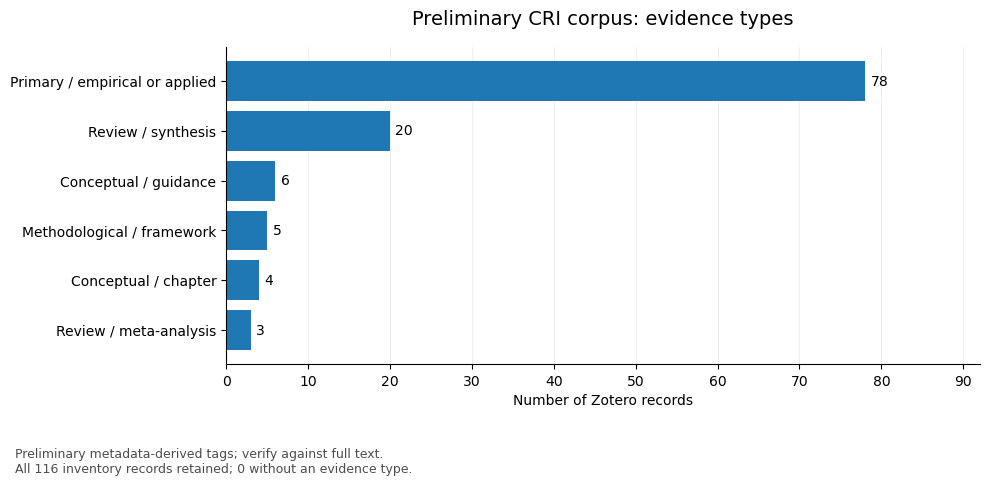

In [6]:
fig = save_bar_chart(
    evidence, 'Preliminary CRI corpus: evidence types',
    f'{caution}\nAll {total} inventory records retained; '
    f'{total - sum(evidence.values())} without an evidence type.',
    output_dir / 'evidence_type_breakdown.png',
)
plt.show()

## 5. Provisional research settings

Multi-label counts: one record may contribute to several settings. Untagged metadata does not establish that a study has no setting.

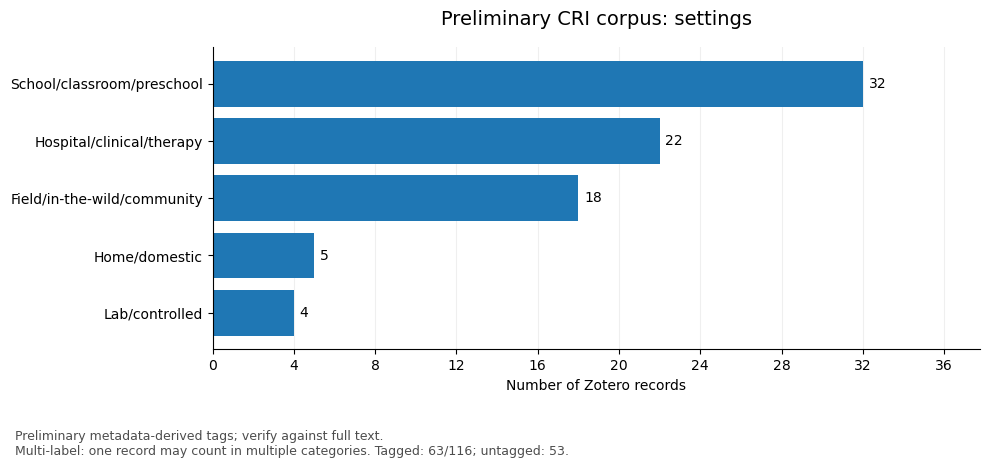

In [7]:
counts, tagged = clusters['settings']
fig = save_bar_chart(
    counts, 'Preliminary CRI corpus: settings',
    f'{caution}\nMulti-label: one record may count in multiple categories. '
    f'Tagged: {tagged}/{total}; untagged: {total - tagged}.',
    output_dir / 'settings_breakdown.png',
)
plt.show()

## 6. Provisional methodology clusters

Use only existing methodology tags. Count each tag separately, including repeated-interaction designs, measures, and robot-control tags already present in the inventory.

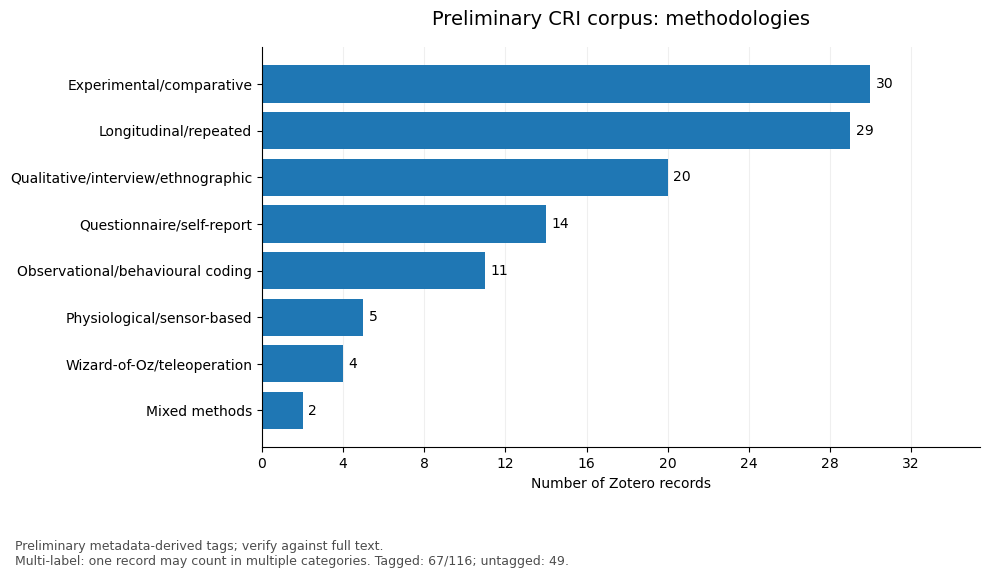

In [8]:
counts, tagged = clusters['methodologies']
fig = save_bar_chart(
    counts, 'Preliminary CRI corpus: methodologies',
    f'{caution}\nMulti-label: one record may count in multiple categories. '
    f'Tagged: {tagged}/{total}; untagged: {total - tagged}.',
    output_dir / 'methodologies_breakdown.png',
)
plt.show()

## 7. Provisional topic clusters

Keep the spreadsheet's topic taxonomy. Multi-label category totals may exceed the number of records.

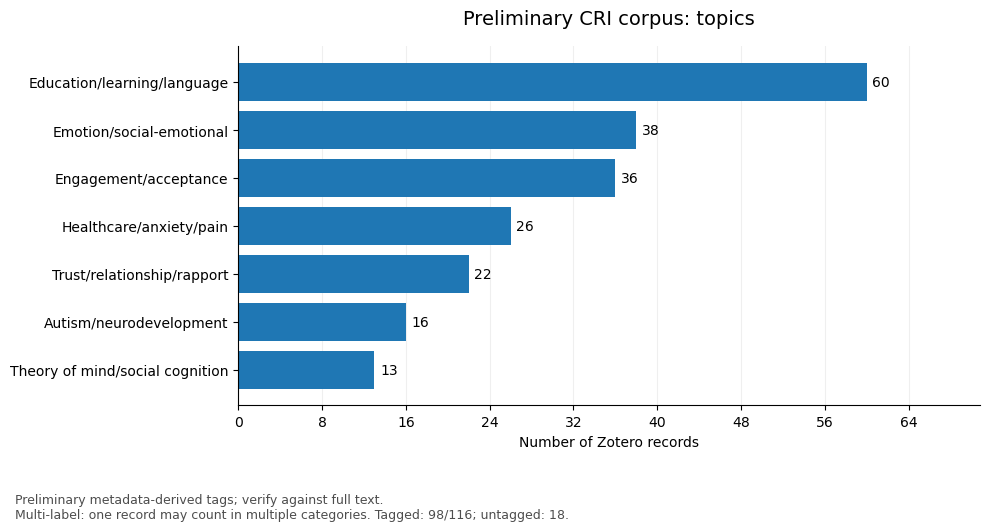

In [9]:
counts, tagged = clusters['topics']
fig = save_bar_chart(
    counts, 'Preliminary CRI corpus: topics',
    f'{caution}\nMulti-label: one record may count in multiple categories. '
    f'Tagged: {tagged}/{total}; untagged: {total - tagged}.',
    output_dir / 'topics_breakdown.png',
)
plt.show()

## 8. Publication years

Show valid whole publication years as recorded, including future-dated records. Report missing or invalid years. This chart describes the collected corpus; it does not establish publication trends across the field.

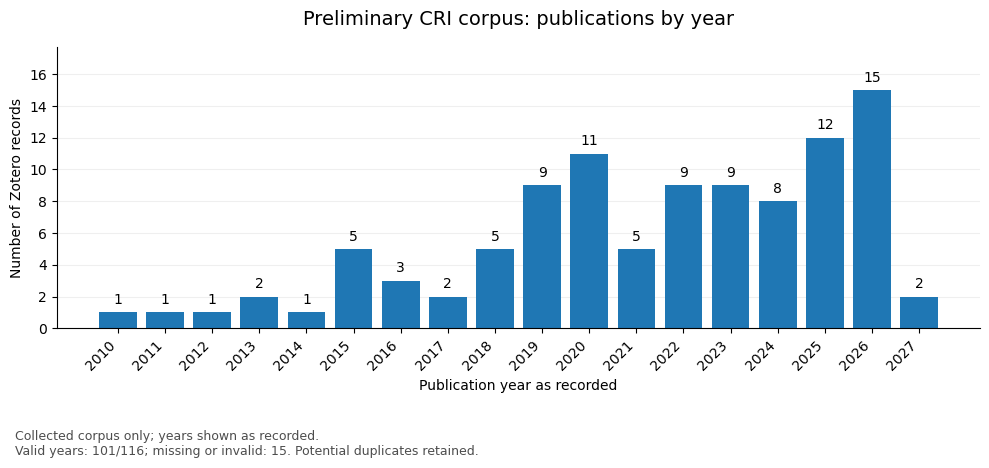

In [10]:
fig = save_bar_chart(
    years if sum(years.values()) >= 2 else {},
    'Preliminary CRI corpus: publications by year',
    f'Collected corpus only; years shown as recorded.\nValid years: '
    f'{sum(years.values())}/{total}; missing or invalid: {missing_years}. '
    'Potential duplicates retained.',
    output_dir / 'publications_by_year.png', by_year=True,
)
plt.show()

## 9. Count-based text summary and saved outputs

Generate the narrative from the calculated counts. The five charts above and this UTF-8 text summary are saved beside the workbook in `corpus_summary_outputs/`.

In [11]:
summary = build_summary(
    data, mapping, sheet, workbook, evidence, clusters, years, missing_years
)
(output_dir / 'corpus_summary.txt').write_text(summary, encoding='utf-8')
print(summary)
print(f'Five charts and corpus_summary.txt saved to: {output_dir}')

Preliminary CRI literature corpus

These classifications are preliminary automated/metadata-derived tags and should not be interpreted as final findings of the narrative review.

Source: 05_CRI_Preliminary_Corpus_Inventory.xlsx; sheet: Inventory
Detected columns: citekey, title, year, authors, venue, doi, bibtex_type, evidence_type, setting_tags, methodology_tags, topic_tags, population_tags, screening_status, priority, manual_notes, dedupe_key

Total number of Zotero records: 116
Journal articles: 76
Conference papers: 19
Bibliographic counts use the existing record type, not venue-based inference.
Potential duplicates: 1 flagged group(s), 2 records involved, 1 extra record(s) if confirmed (from the inventory's existing dedupe_key).
All inventory records are retained; no potential duplicates were removed.

Provisional evidence types:
- Primary / empirical or applied: 78
- Review / synthesis: 20
- Conceptual / guidance: 6
- Methodological / framework: 5
- Conceptual / chapter: 4
- Revi